# SurvSHAP global feature importance — model comparison

Compares the time-integrated (aggregate) SurvSHAP global feature importance across Cox, RSF, GBM and SSVM.
Each source CSV comes from the SurvSHAP section of that model's own notebook (`cox.ipynb`, `rsf.ipynb`,
`gbm.ipynb`, `ssvm.ipynb`): a single point estimate on the whole cohort (3228 patients, 27 events after the
5-year cut-off), no bootstrap/CI, no time-dependent curves — see those notebooks for the per-model plots.

All four share the same background sample, the same explained sample and the same 20-point timestamp grid,
which is what makes `aggregated_change` comparable between them.

Read the **grouped** chart at the bottom for the categorical variables: Cox is fit on the drop_first
encoding and the other three are not, so per-dummy magnitudes are not comparable for those.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


## Load per-model global importance

In [3]:
# (model name, csv path, bar colour). All four CSVs are written by the SurvSHAP
# section of that model's own notebook, on the same cohort, the same background
# and explained samples, and the same timestamp grid -- see the shared protocol
# cell in cox.ipynb / rsf.ipynb / gbm.ipynb / ssvm.ipynb.
#
# RSF is the one produced by exact TreeSHAP rather than the sampling estimator
# (a 2000-tree forest is far too expensive to evaluate the sampling way); both
# target the same interventional Shapley values, and were cross-checked at
# Spearman 0.9995 on a reduced setting.
MODEL_SOURCES = [
    ("Cox",  "cox_survshap_global_importance.csv",  plt.cm.Blues(0.65)),
    ("RSF",  "rsf_survshap_global_importance.csv",  plt.cm.Greens(0.65)),
    ("GBM",  "gbm_survshap_global_importance.csv",  plt.cm.Oranges(0.65)),
    ("SSVM", "ssvm_survshap_global_importance.csv", plt.cm.Purples(0.65)),
]

# Radiotherapy (RT) performed was dropped from the shared treatment-variable list
# after these CSVs were written (data/treatment.txt and data_cox/treatment.txt no
# longer include it). Cox was refit and its CSV regenerated, so it is simply
# absent there; RSF/GBM/SSVM are reused as-is from their last run and still carry
# it. Rather than recompute those three (RSF alone is a ~4-6h exact-TreeSHAP
# run), it is dropped here so a feature none of the four models currently use
# does not appear in a cross-model comparison.
EXCLUDED_VARIABLES = ["Radiotherapy (RT) performed"]

model_importance = {}
for name, path, _ in MODEL_SOURCES:
    df = pd.read_csv(path)
    df = df[~df["variable_name"].isin(EXCLUDED_VARIABLES)].reset_index(drop=True)
    model_importance[name] = df
    print(f"{name}: {len(df)} features")

Cox: 29 features
RSF: 34 features
GBM: 34 features
SSVM: 34 features


## Comparison plot: global feature importance per model

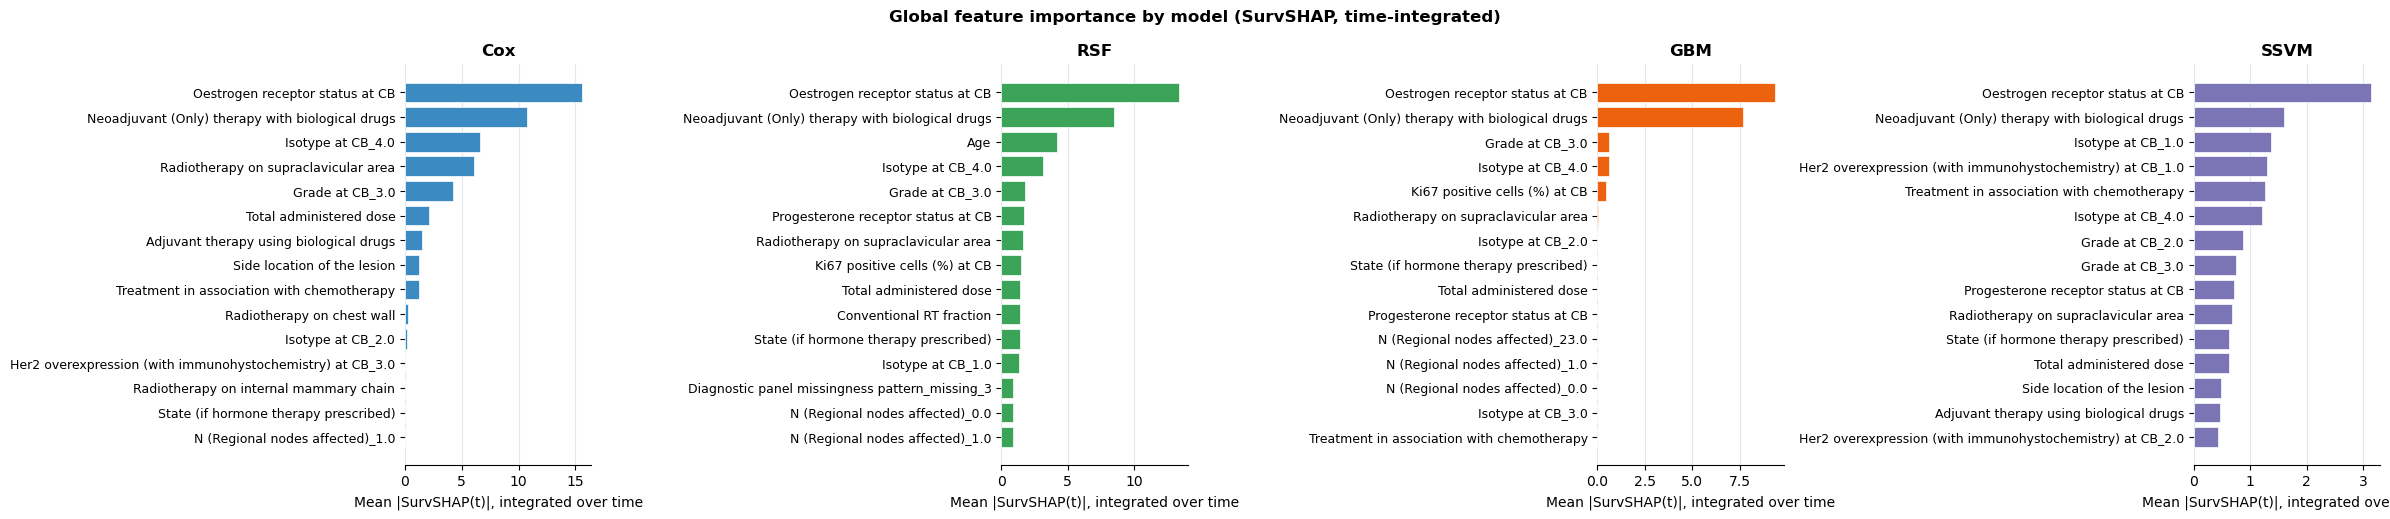

In [4]:
top_n = 15
n_models = len(MODEL_SOURCES)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, max(4, 0.35 * top_n)))
if n_models == 1:
    axes = [axes]

for (name, _, color), ax in zip(MODEL_SOURCES, axes):
    df = model_importance[name].sort_values("aggregated_change", ascending=False).head(top_n)
    df = df.sort_values("aggregated_change", ascending=True)
    y_pos = np.arange(len(df))
    ax.barh(y_pos, df["aggregated_change"], color=color, edgecolor="white", linewidth=0.5)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df["variable_name"], fontsize=9)
    ax.set_xlabel("Mean |SurvSHAP(t)|, integrated over time")
    ax.set_title(name, fontweight="bold")
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

fig.suptitle("Global feature importance by model (SurvSHAP, time-integrated)", fontweight="bold")
plt.tight_layout()
plt.savefig("shap_comparison_global_importance.png", dpi=300, transparent=True, bbox_inches="tight")
plt.savefig("shap_comparison_global_importance.pdf", transparent=True, bbox_inches="tight")
plt.show()


## Feature-rank agreement across models

Spearman correlation between each pair of models' feature-importance rankings (only features present in both models' output are compared).

        Cox    RSF    GBM   SSVM
Cox   1.000  0.453  0.657  0.680
RSF   0.453  1.000  0.621  0.573
GBM   0.657  0.621  1.000  0.469
SSVM  0.680  0.573  0.469  1.000


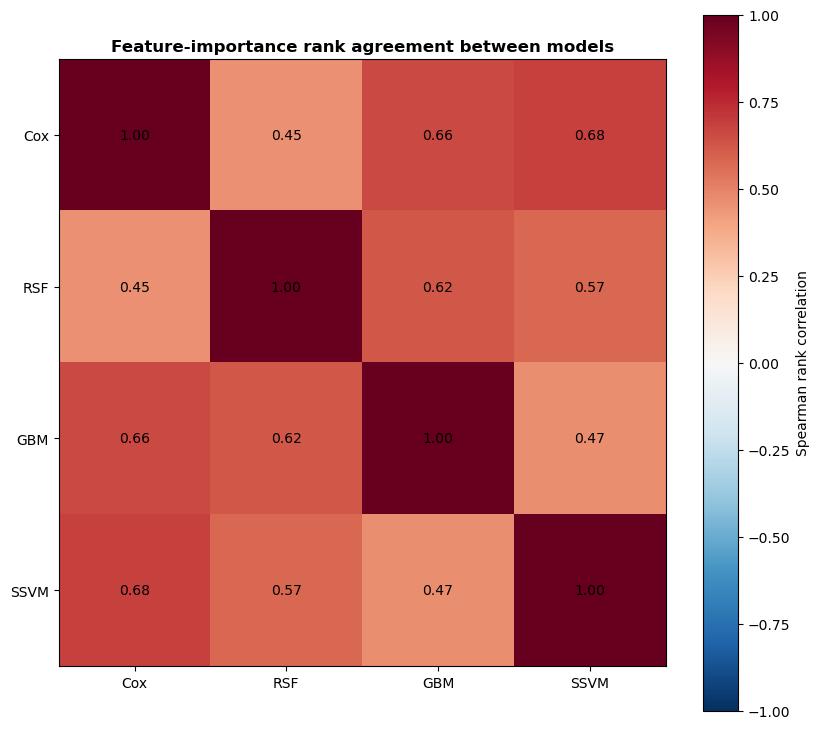

In [5]:
model_names = [name for name, _, _ in MODEL_SOURCES]
rank_series = {
    name: model_importance[name].set_index("variable_name")["aggregated_change"].rank(ascending=False)
    for name in model_names
}

corr_matrix = pd.DataFrame(index=model_names, columns=model_names, dtype=float)
for a in model_names:
    for b in model_names:
        joined = pd.concat([rank_series[a], rank_series[b]], axis=1, join="inner")
        corr_matrix.loc[a, b] = spearmanr(joined.iloc[:, 0], joined.iloc[:, 1]).correlation

corr_matrix.to_csv("shap_comparison_rank_correlation.csv")
print(corr_matrix.round(3).to_string())

fig, ax = plt.subplots(figsize=(1.6 * len(model_names) + 2, 1.6 * len(model_names) + 1))
im = ax.imshow(corr_matrix.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(model_names)))
ax.set_yticks(range(len(model_names)))
ax.set_xticklabels(model_names)
ax.set_yticklabels(model_names)
for i in range(len(model_names)):
    for j in range(len(model_names)):
        ax.text(j, i, f"{corr_matrix.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
fig.colorbar(im, ax=ax, label="Spearman rank correlation")
ax.set_title("Feature-importance rank agreement between models", fontweight="bold")
plt.tight_layout()
plt.savefig("shap_comparison_rank_correlation.png", dpi=300, transparent=True, bbox_inches="tight")
plt.show()


## Importance grouped by source variable

The only view of the categorical variables that is valid across the two dummy encodings.

                                                    Cox      RSF     GBM    SSVM
source_variable                                                                 
ER status                                       15.6217  13.3724  9.3542  3.1448
Neoadjuvant-only biological therapy             10.7237   8.5266  7.6674  1.6045
Isotype                                          6.7293   4.5714  0.6180  2.6867
Grade                                            4.2054   2.4342  0.6264  1.9983
Radiotherapy on supraclavicular area             6.0510   1.6751  0.0162  0.6847
Age                                              0.0000   4.2417  0.0000  0.3471
Total administered dose                          2.1172   1.4298  0.0000  0.6257
Treatment in association with chemotherapy       1.2017   0.2749  0.0000  1.2669
Her2 overexpression                              0.0000   0.8375  0.0000  1.8131
Side location of the lesion                      1.2571   0.7255  0.0000  0.4921
Progesterone receptor status

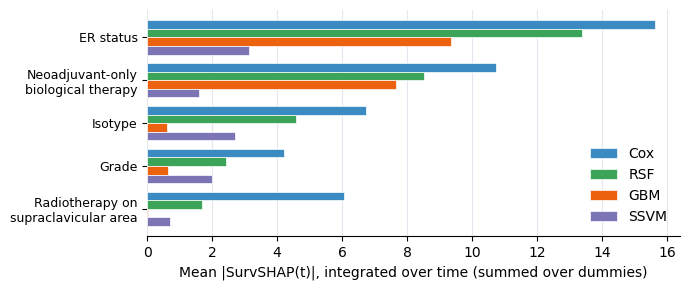


Rank agreement on grouped importance:
      Cox    RSF    GBM   SSVM
Cox   NaN    NaN    NaN    NaN
RSF   NaN  1.000  0.676  0.621
GBM   NaN  0.676  1.000  0.573
SSVM  NaN  0.621  0.573  1.000


In [6]:
# --- Importance grouped back to the source clinical variable ----------------
# The Cox model is fit on the drop_first build (`data/data_cox/`, 30 columns);
# RSF, GBM and SSVM are fit on the full-dummy build (`data/`, 35 columns). The
# five extra columns are reference levels, so a categorical's importance is
# split across 3 dummies for RSF/GBM/SSVM but only 2 for Cox -- and the
# per-feature chart above cannot be read across models for those variables. The
# inner join in the rank correlation below silently drops them entirely.
#
# Summing |SurvSHAP| over the dummies of one categorical puts every model back
# on the same footing. It is a mild overestimate when a categorical's dummies
# have attributions of opposite sign at the same timestamp, but it is the
# standard way to group one-hot features and it is the only comparison of these
# variables that is valid across the two encodings.~

VARIABLE_MAPPING = {
    "Oestrogen receptor status at CB": "ER status",
    "Neoadjuvant (Only) therapy with biological drugs": "Neoadjuvant-only biological therapy",
    "Isotype at CB": "Isotype",
    "Radiotherapy (RT) performed": "Radiotherapy",
    "Grade at CB": "Grade",
    "Radiotherapy on supraclavicular area": "Radiotherapy on supraclavicular area",
    "Age": "Age",
    "Her2 overexpression (with immunohystochemistry) at CB": "Her2 overexpression",
}


def source_variable(name):
    for prefix, source in VARIABLE_MAPPING.items():
        if name == prefix or name.startswith(prefix + "_"):
            return source
    return name


grouped = {}
for name, _, _ in MODEL_SOURCES:
    df = model_importance[name].copy()
    df["source_variable"] = df["variable_name"].map(source_variable)
    grouped[name] = df.groupby("source_variable")["aggregated_change"].sum()

grouped_df = pd.DataFrame(grouped)
grouped_df = grouped_df.loc[grouped_df.mean(axis=1).sort_values(ascending=False).index]
grouped_df.to_csv("shap_comparison_grouped_importance.csv")
print(grouped_df.round(4).to_string())

# Grouped side-by-side chart
top_n = 5
plot_df = grouped_df.head(top_n).iloc[::-1]
y_pos = np.arange(len(plot_df))
bar_h = 0.8 / len(MODEL_SOURCES)

fig, ax = plt.subplots(figsize=(7, max(3.0, 0.30 * len(plot_df))))
ax.set_facecolor("none")
fig.patch.set_alpha(0.0)
for k, (name, _, color) in enumerate(MODEL_SOURCES):
    # Calculate the y-position to stack from top to bottom
    adjusted_y = y_pos + (len(MODEL_SOURCES) - 1 - k) * bar_h
    ax.barh(adjusted_y, plot_df[name], height=bar_h, color=color,
            edgecolor="white", linewidth=0.5, label=name, zorder=3)
import textwrap

# Wrap the y-axis labels to a maximum character width per line (e.g., 20)
wrapped_labels = [textwrap.fill(str(label), width=25) for label in plot_df.index]

ax.set_yticks(y_pos + bar_h * (len(MODEL_SOURCES) - 1) / 2)
ax.set_yticklabels(wrapped_labels, fontsize=9)
ax.set_xlabel("Mean |SurvSHAP(t)|, integrated over time (summed over dummies)")
ax.grid(axis="x", color="#E2E8F0", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("shap_comparison_grouped_importance.png", dpi=300, transparent=True, bbox_inches="tight")
plt.savefig("shap_comparison_grouped_importance.pdf", transparent=True, bbox_inches="tight")
plt.show()

# Rank agreement on the grouped table -- unlike the per-feature matrix above,
# this one compares all variables, including the categoricals.
grouped_ranks = grouped_df.rank(ascending=False)
grouped_corr = pd.DataFrame(index=grouped_df.columns, columns=grouped_df.columns, dtype=float)
for a in grouped_df.columns:
    for b in grouped_df.columns:
        grouped_corr.loc[a, b] = spearmanr(grouped_ranks[a], grouped_ranks[b]).correlation
grouped_corr.to_csv("shap_comparison_grouped_rank_correlation.csv")
print("\nRank agreement on grouped importance:")
print(grouped_corr.round(3).to_string())